# modeling_5th_experiment

`modeling_4th_elo.ipynb`의 ELO SP feature set만 사용하고, Logistic Regression을 baseline으로 삼아 XGBoost, LightGBM, ensemble, MLP를 같은 split/metric에서 비교한다.

- tuning split: 2023 train -> 2024 validation
- final evaluation: 2023+2024 train -> 2025 test
- feature contract: `feature_cols_elo_sp.pkl`만 사용


In [1]:
import importlib
import itertools
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    log_loss,
    roc_auc_score,
    roc_curve,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import utils as ut
importlib.reload(ut)

warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_STATE = 427
pd.set_option("display.max_columns", 120)

In [2]:
def optional_imports():
    libs = {}

    try:
        from xgboost import XGBClassifier
        libs["xgboost"] = XGBClassifier
    except Exception as e:
        libs["xgboost"] = None
        print(f"[skip] xgboost import failed: {type(e).__name__}: {e}")

    try:
        from lightgbm import LGBMClassifier
        libs["lightgbm"] = LGBMClassifier
    except Exception as e:
        libs["lightgbm"] = None
        print(f"[skip] lightgbm import failed: {type(e).__name__}: {e}")

    return libs


OPTIONAL_MODELS = optional_imports()

## 1. Load Data And Rebuild 4th ELO Features

In [3]:
df23 = pd.read_csv("model_df_2023.csv")
df24 = pd.read_csv("model_df_2024.csv")
df25 = pd.read_csv("model_df_2025.csv")

base_df = pd.concat([df23, df24, df25], axis=0, ignore_index=True)
base_df["game_date"] = pd.to_datetime(base_df["game_date"], errors="coerce")

for col in ["home_score", "away_score", "home_win", "y_home_win", "season"]:
    if col in base_df.columns:
        base_df[col] = pd.to_numeric(base_df[col], errors="coerce")

base_df["elo_result_home"] = np.where(
    base_df["home_score"] > base_df["away_score"], 1.0,
    np.where(base_df["home_score"] < base_df["away_score"], 0.0, 0.5),
)

base_df = base_df.sort_values(["game_date", "game_id"]).reset_index(drop=True)
base_df[["season", "game_id", "game_date", "home_team_code", "away_team_code", "home_score", "away_score"]].head()

,season,game_id,game_date,home_team_code,away_team_code,home_score,away_score
0,2023,20230711,2023-03-23 04:00:00,10001,1001,5.0,6.0
1,2023,20230712,2023-03-23 04:00:00,12001,5002,2.0,6.0
2,2023,20230716,2023-03-24 04:00:00,10001,1001,3.0,4.0
3,2023,20230717,2023-03-24 04:00:00,12001,5002,7.0,1.0
4,2023,20230718,2023-03-24 04:00:00,7002,6002,3.0,10.0


In [4]:
def make_team_game_log(game_df: pd.DataFrame) -> pd.DataFrame:
    base_cols = ["game_id", "game_date", "season"]

    home = game_df[base_cols + ["home_team_code", "away_team_code", "home_score", "away_score", "elo_result_home"]].copy()
    home = home.rename(columns={
        "home_team_code": "team_code",
        "away_team_code": "opponent_team_code",
        "home_score": "runs_for",
        "away_score": "runs_against",
        "elo_result_home": "result",
    })
    home["is_home"] = 1

    away = game_df[base_cols + ["away_team_code", "home_team_code", "away_score", "home_score", "elo_result_home"]].copy()
    away = away.rename(columns={
        "away_team_code": "team_code",
        "home_team_code": "opponent_team_code",
        "away_score": "runs_for",
        "home_score": "runs_against",
    })
    away["result"] = 1.0 - pd.to_numeric(away["elo_result_home"], errors="coerce")
    away = away.drop(columns=["elo_result_home"])
    away["is_home"] = 0

    team_games = pd.concat([home, away], ignore_index=True)
    team_games["game_date"] = pd.to_datetime(team_games["game_date"], errors="coerce")
    team_games["team_code"] = team_games["team_code"].astype(str)
    team_games["opponent_team_code"] = team_games["opponent_team_code"].astype(str)
    team_games["runs_for"] = pd.to_numeric(team_games["runs_for"], errors="coerce")
    team_games["runs_against"] = pd.to_numeric(team_games["runs_against"], errors="coerce")
    team_games["result"] = pd.to_numeric(team_games["result"], errors="coerce")
    team_games["run_diff"] = team_games["runs_for"] - team_games["runs_against"]

    return team_games.sort_values(["team_code", "game_date", "game_id"]).reset_index(drop=True)


def build_recent_team_features(game_df: pd.DataFrame, windows=(5, 10)):
    team_recent = make_team_game_log(game_df)
    team_recent = team_recent.sort_values(["team_code", "game_date", "game_id"]).reset_index(drop=True)
    grouped = team_recent.groupby(["team_code", "season"], group_keys=False)

    team_recent["prev_game_date"] = grouped["game_date"].shift(1)
    team_recent["rest_days"] = (team_recent["game_date"].dt.normalize() - team_recent["prev_game_date"].dt.normalize()).dt.days - 1
    team_recent["rest_days"] = team_recent["rest_days"].clip(lower=0)
    team_recent["prev_game_result"] = grouped["result"].shift(1)

    rolling_targets = {
        "result": "result_avg",
        "runs_for": "runs_for_avg",
        "runs_against": "runs_against_avg",
        "run_diff": "run_diff_avg",
    }

    for window in windows:
        for src_col, out_name in rolling_targets.items():
            out_col = f"recent_{window}_{out_name}"
            team_recent[out_col] = grouped[src_col].transform(
                lambda s, w=window: s.shift(1).rolling(w, min_periods=1).mean()
            )

    feature_cols = ["game_id", "team_code", "rest_days", "prev_game_result"]
    feature_cols += [c for c in team_recent.columns if c.startswith("recent_")]
    recent_features = team_recent[feature_cols].copy()

    home_recent = recent_features.rename(
        columns={c: f"home_{c}" for c in feature_cols if c not in ["game_id", "team_code"]}
    ).rename(columns={"team_code": "home_team_code"})
    away_recent = recent_features.rename(
        columns={c: f"away_{c}" for c in feature_cols if c not in ["game_id", "team_code"]}
    ).rename(columns={"team_code": "away_team_code"})

    out = game_df.copy()
    out["home_team_code"] = out["home_team_code"].astype(str)
    out["away_team_code"] = out["away_team_code"].astype(str)
    out = out.merge(home_recent, on=["game_id", "home_team_code"], how="left")
    out = out.merge(away_recent, on=["game_id", "away_team_code"], how="left")

    diff_pairs = ["rest_days", "prev_game_result"] + [c for c in team_recent.columns if c.startswith("recent_")]
    for col in diff_pairs:
        out[f"{col}_diff"] = out[f"home_{col}"] - out[f"away_{col}"]

    return out, team_recent


model_base_df, team_recent = build_recent_team_features(base_df, windows=(5, 10))
model_base_df.shape

(2114, 101)

In [5]:
FINAL_ALPHA = 0.65
FINAL_HOME_FIELD_ADV = 25
BASE_ELO = 1500.0
K_FACTOR = 20.0


def expected_home_score(home_elo: float, away_elo: float, home_field_adv: float = 0.0) -> float:
    return 1.0 / (1.0 + 10 ** (((away_elo) - (home_elo + home_field_adv)) / 400.0))


def regress_to_mean(old_elo: float, alpha: float, base_elo: float = 1500.0) -> float:
    return base_elo + alpha * (old_elo - base_elo)


def build_elo_features(
    game_df: pd.DataFrame,
    alpha: float = FINAL_ALPHA,
    home_field_adv: float = FINAL_HOME_FIELD_ADV,
    base_elo: float = BASE_ELO,
    k_factor: float = K_FACTOR,
) -> pd.DataFrame:
    elo_df = game_df.copy().sort_values(["game_date", "game_id"]).reset_index(drop=True)
    elo_df["home_team_code"] = elo_df["home_team_code"].astype(str)
    elo_df["away_team_code"] = elo_df["away_team_code"].astype(str)

    ratings = {}
    last_seen_season = {}
    home_elo_pre_list = []
    away_elo_pre_list = []
    elo_exp_home_list = []
    home_elo_post_list = []
    away_elo_post_list = []

    for row in elo_df.itertuples(index=False):
        season = row.season
        home_team = row.home_team_code
        away_team = row.away_team_code

        for team in [home_team, away_team]:
            if team not in ratings:
                ratings[team] = base_elo
                last_seen_season[team] = season
            elif last_seen_season[team] != season:
                ratings[team] = regress_to_mean(ratings[team], alpha=alpha, base_elo=base_elo)
                last_seen_season[team] = season

        result_home = row.elo_result_home
        home_elo_pre = ratings[home_team]
        away_elo_pre = ratings[away_team]
        elo_exp_home = expected_home_score(home_elo_pre, away_elo_pre, home_field_adv=home_field_adv)

        elo_delta = k_factor * (result_home - elo_exp_home)
        home_elo_post = home_elo_pre + elo_delta
        away_elo_post = away_elo_pre - elo_delta

        ratings[home_team] = home_elo_post
        ratings[away_team] = away_elo_post
        last_seen_season[home_team] = season
        last_seen_season[away_team] = season

        home_elo_pre_list.append(home_elo_pre)
        away_elo_pre_list.append(away_elo_pre)
        elo_exp_home_list.append(elo_exp_home)
        home_elo_post_list.append(home_elo_post)
        away_elo_post_list.append(away_elo_post)

    elo_df["home_elo_pre"] = home_elo_pre_list
    elo_df["away_elo_pre"] = away_elo_pre_list
    elo_df["elo_diff"] = elo_df["home_elo_pre"] - elo_df["away_elo_pre"]
    elo_df["elo_exp_home"] = elo_exp_home_list
    elo_df["home_elo_post"] = home_elo_post_list
    elo_df["away_elo_post"] = away_elo_post_list

    return elo_df


final_df = build_elo_features(model_base_df)
final_df[["game_id", "game_date", "home_elo_pre", "away_elo_pre", "elo_diff", "elo_exp_home"]].head()

,game_id,game_date,home_elo_pre,away_elo_pre,elo_diff,elo_exp_home
0,20230711,2023-03-23 04:00:00,1500.000000,1500.000000,0.000000,0.535916
1,20230712,2023-03-23 04:00:00,1500.000000,1500.000000,0.000000,0.535916
2,20230716,2023-03-24 04:00:00,1489.281681,1510.718319,-21.436637,0.505128
3,20230717,2023-03-24 04:00:00,1489.281681,1510.718319,-21.436637,0.505128
4,20230718,2023-03-24 04:00:00,1500.000000,1500.000000,0.000000,0.535916


## 2. Feature Contract

In [6]:
elo_feature_candidates = ["home_elo_pre", "away_elo_pre", "elo_diff", "elo_exp_home"]
sp_feature_candidates = ["sp_ERA_diff", "sp_FIP_diff", "sp_WHIP_diff", "sp_K9_diff", "sp_BB9_diff", "sp_HR9_diff", "sp_KBB_diff"]
recent_feature_candidates = [
    "recent_5_result_avg_diff",
    "recent_5_runs_for_avg_diff",
    "recent_5_runs_against_avg_diff",
    "recent_5_run_diff_avg_diff",
    "recent_10_result_avg_diff",
    "recent_10_runs_for_avg_diff",
    "recent_10_runs_against_avg_diff",
    "recent_10_run_diff_avg_diff",
    "rest_days_diff",
    "prev_game_result_diff",
]


def load_feature_cols(path, fallback):
    path = Path(path)
    if path.exists():
        cols = joblib.load(path)
        return [c for c in cols if c in final_df.columns]
    return [c for c in fallback if c in final_df.columns]


feature_cols_elo_sp = load_feature_cols(
    "feature_cols_elo_sp.pkl",
    sp_feature_candidates + recent_feature_candidates + elo_feature_candidates,
)

# 이번 실험은 모든 모델이 동일한 elo_sp 컬럼만 사용한다.
FEATURE_SET_NAME = "elo_sp"
FEATURE_COLS = feature_cols_elo_sp
feature_sets = {FEATURE_SET_NAME: FEATURE_COLS}

recent_cols_in_model = [c for c in recent_feature_candidates if c in final_df.columns]
final_model_input = final_df.copy()
final_model_input[recent_cols_in_model] = final_model_input[recent_cols_in_model].fillna(0)

print(FEATURE_SET_NAME, len(FEATURE_COLS), FEATURE_COLS)


elo_sp 13 ['sp_FIP_diff', 'sp_ERA_diff', 'sp_K9_diff', 'sp_BB9_diff', 'sp_HR9_diff', 'sp_KBB_diff', 'recent_5_run_diff_avg_diff', 'recent_5_runs_against_avg_diff', 'rest_days_diff', 'home_elo_pre', 'away_elo_pre', 'elo_diff', 'elo_exp_home']


In [7]:
train_2023_df = final_model_input[final_model_input["season"] == 2023].copy()
valid_2024_df = final_model_input[final_model_input["season"] == 2024].copy()
train_2324_df = final_model_input[final_model_input["season"] <= 2024].copy()
test_2025_df = final_model_input[final_model_input["season"] == 2025].copy()

split_summary = pd.DataFrame({
    "split": ["train_2023", "valid_2024", "train_2324", "test_2025"],
    "n": [len(train_2023_df), len(valid_2024_df), len(train_2324_df), len(test_2025_df)],
})
split_summary

,split,n
0,train_2023,688
1,valid_2024,717
2,train_2324,1405
3,test_2025,709


## 3. Evaluation Helpers

In [8]:
def make_ready_xy(df, feature_cols, target_col="y_home_win"):
    ready = df.dropna(subset=feature_cols + [target_col]).copy()
    X = ready[feature_cols].astype(float)
    y = ready[target_col].astype(int)
    return ready, X, y


def get_positive_proba(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    scores = model.decision_function(X)
    return 1.0 / (1.0 + np.exp(-scores))


def metric_dict(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    out = {
        "acc": accuracy_score(y_true, pred),
        "auc": roc_auc_score(y_true, proba),
        "brier": brier_score_loss(y_true, proba),
        "logloss": log_loss(y_true, proba, labels=[0, 1]),
    }
    return out


def evaluate_fitted_model(model_name, model, feature_set_name, feature_cols, fit_df, eval_df, best_params=None):
    fit_ready, X_fit, y_fit = make_ready_xy(fit_df, feature_cols)
    eval_ready, X_eval, y_eval = make_ready_xy(eval_df, feature_cols)

    start = time.time()
    model.fit(X_fit, y_fit)
    fit_seconds = time.time() - start

    fit_proba = get_positive_proba(model, X_fit)
    eval_proba = get_positive_proba(model, X_eval)
    fit_metrics = metric_dict(y_fit, fit_proba)
    eval_metrics = metric_dict(y_eval, eval_proba)

    result = {
        "model": model_name,
        "feature_set": feature_set_name,
        "n_features": len(feature_cols),
        "fit_n": len(fit_ready),
        "eval_n": len(eval_ready),
        "fit_seconds": fit_seconds,
        "best_params": best_params,
    }
    result.update({f"fit_{k}": v for k, v in fit_metrics.items()})
    result.update({f"eval_{k}": v for k, v in eval_metrics.items()})

    pred_df = eval_ready[["game_id", "game_date", "season", "home_team_code", "away_team_code", "home_score", "away_score"]].copy()
    pred_df["model"] = model_name
    pred_df["feature_set"] = feature_set_name
    pred_df["y_true"] = y_eval.values
    pred_df["y_proba"] = eval_proba
    pred_df["y_pred"] = (eval_proba >= 0.5).astype(int)
    pred_df["correct"] = (pred_df["y_true"] == pred_df["y_pred"]).astype(int)
    return result, pred_df


def tune_on_2024(model_name, build_model, param_grid, feature_cols, score_col="auc"):
    rows = []
    best = None

    _, X_train, y_train = make_ready_xy(train_2023_df, feature_cols)
    _, X_valid, y_valid = make_ready_xy(valid_2024_df, feature_cols)

    keys = list(param_grid.keys())
    for values in itertools.product(*[param_grid[k] for k in keys]):
        params = dict(zip(keys, values))
        model = build_model(**params)
        start = time.time()
        model.fit(X_train, y_train)
        fit_seconds = time.time() - start
        valid_proba = get_positive_proba(model, X_valid)
        metrics = metric_dict(y_valid, valid_proba)
        row = {"model": model_name, "fit_seconds": fit_seconds, "params": params}
        row.update({f"valid_{k}": v for k, v in metrics.items()})
        rows.append(row)

        score = metrics[score_col]
        if best is None or score > best["score"]:
            best = {"score": score, "params": params, "model": model}

    tuning_df = pd.DataFrame(rows).sort_values([f"valid_{score_col}", "valid_brier"], ascending=[False, True]).reset_index(drop=True)
    return best, tuning_df

## 4. Model Builders And Hyperparameter Grids

In [9]:
def build_logistic(C=1.0, penalty="l2"):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            C=C,
            penalty=penalty,
            solver="lbfgs",
            max_iter=2000,
            random_state=RANDOM_STATE,
        )),
    ])


def build_xgboost(n_estimators=150, max_depth=2, learning_rate=0.05, subsample=0.9, colsample_bytree=0.9, reg_lambda=1.0):
    XGBClassifier = OPTIONAL_MODELS["xgboost"]
    if XGBClassifier is None:
        raise ImportError("xgboost is not installed")
    return XGBClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        learning_rate=learning_rate,
        subsample=subsample,
        colsample_bytree=colsample_bytree,
        reg_lambda=reg_lambda,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )


def build_lightgbm(n_estimators=150, num_leaves=7, learning_rate=0.05, subsample=0.9, colsample_bytree=0.9, reg_lambda=1.0):
    LGBMClassifier = OPTIONAL_MODELS["lightgbm"]
    if LGBMClassifier is None:
        raise ImportError("lightgbm is not installed")
    return LGBMClassifier(
        n_estimators=n_estimators,
        num_leaves=num_leaves,
        learning_rate=learning_rate,
        subsample=subsample,
        colsample_bytree=colsample_bytree,
        reg_lambda=reg_lambda,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=-1,
    )


def build_mlp(hidden_layer_sizes=(32,), alpha=0.001, learning_rate_init=0.001):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", MLPClassifier(
            hidden_layer_sizes=hidden_layer_sizes,
            alpha=alpha,
            learning_rate_init=learning_rate_init,
            activation="relu",
            early_stopping=True,
            validation_fraction=0.2,
            max_iter=1000,
            random_state=RANDOM_STATE,
        )),
    ])


model_specs = {
    "logistic_baseline": {
        "builder": build_logistic,
        "grid": {"C": [0.1, 0.3, 1.0, 3.0], "penalty": ["l2"]},
    },
    "xgboost": {
        "builder": build_xgboost,
        "grid": {
            "n_estimators": [100, 200],
            "max_depth": [2, 3],
            "learning_rate": [0.03, 0.07],
            "subsample": [0.85],
            "colsample_bytree": [0.85],
            "reg_lambda": [1.0, 3.0],
        },
    },
    "lightgbm": {
        "builder": build_lightgbm,
        "grid": {
            "n_estimators": [100, 200],
            "num_leaves": [7, 15],
            "learning_rate": [0.03, 0.07],
            "subsample": [0.85],
            "colsample_bytree": [0.85],
            "reg_lambda": [1.0, 3.0],
        },
    },
    "mlp": {
        "builder": build_mlp,
        "grid": {
            "hidden_layer_sizes": [(16,), (32,), (32, 16)],
            "alpha": [0.0005, 0.001, 0.005],
            "learning_rate_init": [0.001],
        },
    },
}

## 5. Tune On 2024, Evaluate On 2025

In [10]:
tuning_tables = {}
final_results = []
prediction_tables = []
best_models = {}

for feature_set_name, feature_cols in feature_sets.items():
    print(f"\n===== feature set: {feature_set_name} ({len(feature_cols)} cols) =====")

    for model_name, spec in model_specs.items():
        if model_name == "xgboost" and OPTIONAL_MODELS["xgboost"] is None:
            continue
        if model_name == "lightgbm" and OPTIONAL_MODELS["lightgbm"] is None:
            continue

        print(f"tuning: {model_name}")
        best, tuning_df = tune_on_2024(
            model_name=model_name,
            build_model=spec["builder"],
            param_grid=spec["grid"],
            feature_cols=feature_cols,
            score_col="auc",
        )
        tuning_df.insert(0, "feature_set", feature_set_name)
        tuning_tables[(feature_set_name, model_name)] = tuning_df

        final_model = spec["builder"](**best["params"])
        result, pred_df = evaluate_fitted_model(
            model_name=model_name,
            model=final_model,
            feature_set_name=feature_set_name,
            feature_cols=feature_cols,
            fit_df=train_2324_df,
            eval_df=test_2025_df,
            best_params=best["params"],
        )
        final_results.append(result)
        prediction_tables.append(pred_df)
        best_models[(feature_set_name, model_name)] = final_model

results_df = pd.DataFrame(final_results).sort_values(["eval_auc", "eval_acc"], ascending=False).reset_index(drop=True)
predictions_df = pd.concat(prediction_tables, ignore_index=True) if prediction_tables else pd.DataFrame()
display(results_df.round(4))


===== feature set: elo_sp (13 cols) =====
tuning: logistic_baseline
tuning: xgboost
tuning: lightgbm
tuning: mlp


,model,feature_set,n_features,fit_n,eval_n,fit_seconds,best_params,fit_acc,fit_auc,fit_brier,fit_logloss,eval_acc,eval_auc,eval_brier,eval_logloss
0,logistic_baseline,elo_sp,13,1369,709,0.0115,"{'C': 0.1, 'penalty': 'l2'}",0.6034,0.6455,0.2336,0.6595,0.6262,0.6543,0.2329,0.6578
1,mlp,elo_sp,13,1369,709,0.0873,"{'hidden_layer_sizes': (32,), 'alpha': 0.005, ...",0.5931,0.6377,0.2359,0.6672,0.6065,0.6478,0.2352,0.6943
2,lightgbm,elo_sp,13,1369,709,0.0462,"{'n_estimators': 100, 'num_leaves': 7, 'learni...",0.6815,0.7633,0.2070,0.6029,0.6023,0.6474,0.2341,0.6608
3,xgboost,elo_sp,13,1369,709,0.1169,"{'n_estimators': 100, 'max_depth': 2, 'learnin...",0.6662,0.7453,0.2081,0.6037,0.6079,0.6425,0.2362,0.6654


In [11]:
all_tuning_df = pd.concat(tuning_tables.values(), ignore_index=True) if tuning_tables else pd.DataFrame()

display(
    all_tuning_df
    .groupby(["feature_set", "model"], as_index=False)
    .head(5)
    [["feature_set", "model", "valid_auc", "valid_acc", "valid_brier", "valid_logloss", "params"]]
    .round(4)
)

,feature_set,model,valid_auc,valid_acc,valid_brier,valid_logloss,params
0,elo_sp,logistic_baseline,0.6223,0.5935,0.2409,0.6781,"{'C': 0.1, 'penalty': 'l2'}"
1,elo_sp,logistic_baseline,0.6217,0.5921,0.2412,0.6790,"{'C': 0.3, 'penalty': 'l2'}"
2,elo_sp,logistic_baseline,0.6210,0.5907,0.2414,0.6791,"{'C': 1.0, 'penalty': 'l2'}"
3,elo_sp,logistic_baseline,0.6206,0.5935,0.2414,0.6791,"{'C': 3.0, 'penalty': 'l2'}"
4,elo_sp,xgboost,0.6323,0.5921,0.2391,0.6711,"{'n_estimators': 100, 'max_depth': 2, 'learnin..."
5,elo_sp,xgboost,0.6317,0.5935,0.2391,0.6713,"{'n_estimators': 200, 'max_depth': 2, 'learnin..."
6,elo_sp,xgboost,0.6308,0.5921,0.2388,0.6704,"{'n_estimators': 200, 'max_depth': 2, 'learnin..."
7,elo_sp,xgboost,0.6304,0.5921,0.2408,0.6750,"{'n_estimators': 100, 'max_depth': 2, 'learnin..."
8,elo_sp,xgboost,0.6298,0.5837,0.2449,0.6870,"{'n_estimators': 200, 'max_depth': 2, 'learnin..."
20,elo_sp,lightgbm,0.6219,0.5907,0.2412,0.6756,"{'n_estimators': 100, 'num_leaves': 7, 'learni..."


## 6. Ensemble Experiments

In [12]:
def make_soft_voting(best_params_by_model):
    estimators = []
    estimators.append(("logistic", build_logistic(**best_params_by_model["logistic_baseline"])))
    if "xgboost" in best_params_by_model and OPTIONAL_MODELS["xgboost"] is not None:
        estimators.append(("xgboost", build_xgboost(**best_params_by_model["xgboost"])))
    if "lightgbm" in best_params_by_model and OPTIONAL_MODELS["lightgbm"] is not None:
        estimators.append(("lightgbm", build_lightgbm(**best_params_by_model["lightgbm"])))
    estimators.append(("mlp", build_mlp(**best_params_by_model["mlp"])))
    return VotingClassifier(estimators=estimators, voting="soft", n_jobs=-1)


def make_stacking(best_params_by_model):
    estimators = []
    estimators.append(("logistic", build_logistic(**best_params_by_model["logistic_baseline"])))
    if "xgboost" in best_params_by_model and OPTIONAL_MODELS["xgboost"] is not None:
        estimators.append(("xgboost", build_xgboost(**best_params_by_model["xgboost"])))
    if "lightgbm" in best_params_by_model and OPTIONAL_MODELS["lightgbm"] is not None:
        estimators.append(("lightgbm", build_lightgbm(**best_params_by_model["lightgbm"])))
    estimators.append(("mlp", build_mlp(**best_params_by_model["mlp"])))
    return StackingClassifier(
        estimators=estimators,
        final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        stack_method="predict_proba",
        cv=3,
        n_jobs=-1,
    )


ensemble_results = []
ensemble_predictions = []

for feature_set_name, feature_cols in feature_sets.items():
    best_params_by_model = {}
    for model_name in ["logistic_baseline", "xgboost", "lightgbm", "mlp"]:
        key = (feature_set_name, model_name)
        if key in tuning_tables and len(tuning_tables[key]):
            best_params_by_model[model_name] = tuning_tables[key].iloc[0]["params"]

    if {"logistic_baseline", "mlp"}.issubset(best_params_by_model):
        for ensemble_name, builder in {
            "ensemble_soft_voting": make_soft_voting,
            "ensemble_stacking": make_stacking,
        }.items():
            model = builder(best_params_by_model)
            result, pred_df = evaluate_fitted_model(
                model_name=ensemble_name,
                model=model,
                feature_set_name=feature_set_name,
                feature_cols=feature_cols,
                fit_df=train_2324_df,
                eval_df=test_2025_df,
                best_params=best_params_by_model,
            )
            ensemble_results.append(result)
            ensemble_predictions.append(pred_df)

ensemble_results_df = pd.DataFrame(ensemble_results)
if len(ensemble_results_df):
    results_df = pd.concat([results_df, ensemble_results_df], ignore_index=True)
    results_df = results_df.sort_values(["eval_auc", "eval_acc"], ascending=False).reset_index(drop=True)
    predictions_df = pd.concat([predictions_df] + ensemble_predictions, ignore_index=True)

display(results_df.round(4))

,model,feature_set,n_features,fit_n,eval_n,fit_seconds,best_params,fit_acc,fit_auc,fit_brier,fit_logloss,eval_acc,eval_auc,eval_brier,eval_logloss
0,ensemble_soft_voting,elo_sp,13,1369,709,3.1071,"{'logistic_baseline': {'C': 0.1, 'penalty': 'l...",0.6413,0.7111,0.2189,0.6278,0.6164,0.6550,0.2319,0.6559
1,logistic_baseline,elo_sp,13,1369,709,0.0115,"{'C': 0.1, 'penalty': 'l2'}",0.6034,0.6455,0.2336,0.6595,0.6262,0.6543,0.2329,0.6578
2,ensemble_stacking,elo_sp,13,1369,709,2.7317,"{'logistic_baseline': {'C': 0.1, 'penalty': 'l...",0.6202,0.6946,0.2246,0.6405,0.6220,0.6532,0.2328,0.6578
3,mlp,elo_sp,13,1369,709,0.0873,"{'hidden_layer_sizes': (32,), 'alpha': 0.005, ...",0.5931,0.6377,0.2359,0.6672,0.6065,0.6478,0.2352,0.6943
4,lightgbm,elo_sp,13,1369,709,0.0462,"{'n_estimators': 100, 'num_leaves': 7, 'learni...",0.6815,0.7633,0.2070,0.6029,0.6023,0.6474,0.2341,0.6608
5,xgboost,elo_sp,13,1369,709,0.1169,"{'n_estimators': 100, 'max_depth': 2, 'learnin...",0.6662,0.7453,0.2081,0.6037,0.6079,0.6425,0.2362,0.6654


## 7. Result Review And Save Artifacts

,model,feature_set,n_features,fit_n,eval_n,eval_acc,eval_auc,eval_brier,eval_logloss,best_params
0,ensemble_soft_voting,elo_sp,13,1369,709,0.6164,0.6550,0.2319,0.6559,"{'logistic_baseline': {'C': 0.1, 'penalty': 'l..."
1,logistic_baseline,elo_sp,13,1369,709,0.6262,0.6543,0.2329,0.6578,"{'C': 0.1, 'penalty': 'l2'}"
2,ensemble_stacking,elo_sp,13,1369,709,0.6220,0.6532,0.2328,0.6578,"{'logistic_baseline': {'C': 0.1, 'penalty': 'l..."
3,mlp,elo_sp,13,1369,709,0.6065,0.6478,0.2352,0.6943,"{'hidden_layer_sizes': (32,), 'alpha': 0.005, ..."
4,lightgbm,elo_sp,13,1369,709,0.6023,0.6474,0.2341,0.6608,"{'n_estimators': 100, 'num_leaves': 7, 'learni..."
5,xgboost,elo_sp,13,1369,709,0.6079,0.6425,0.2362,0.6654,"{'n_estimators': 100, 'max_depth': 2, 'learnin..."


,metric,best_model,feature_set,score
0,accuracy,logistic_baseline,elo_sp,0.6262
1,AUC,ensemble_soft_voting,elo_sp,0.6550
2,brier_score,ensemble_soft_voting,elo_sp,0.2319


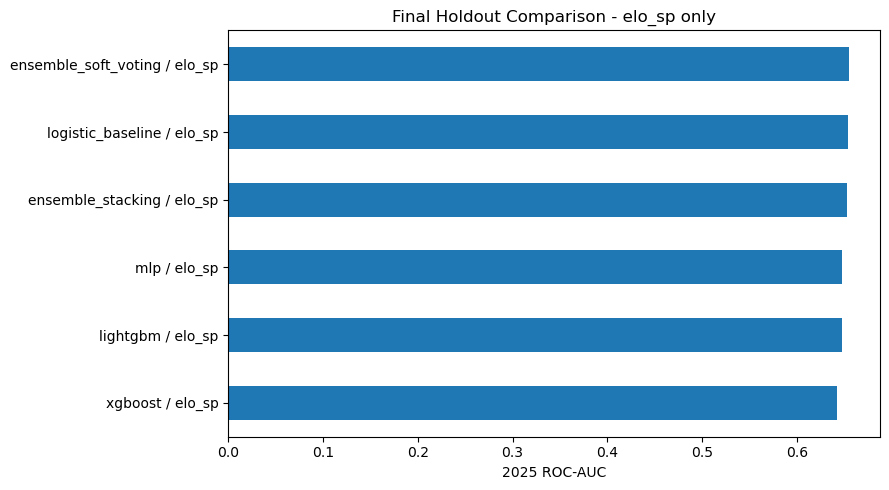

In [13]:
metric_cols = ["model", "feature_set", "n_features", "fit_n", "eval_n", "eval_acc", "eval_auc", "eval_brier", "eval_logloss", "best_params"]
display(results_df[metric_cols].round(4))

best_accuracy_row = results_df.loc[results_df["eval_acc"].idxmax()]
best_auc_row = results_df.loc[results_df["eval_auc"].idxmax()]
best_brier_row = results_df.loc[results_df["eval_brier"].idxmin()]

best_metric_summary = pd.DataFrame([
    {"metric": "accuracy", "best_model": best_accuracy_row["model"], "feature_set": best_accuracy_row["feature_set"], "score": best_accuracy_row["eval_acc"]},
    {"metric": "AUC", "best_model": best_auc_row["model"], "feature_set": best_auc_row["feature_set"], "score": best_auc_row["eval_auc"]},
    {"metric": "brier_score", "best_model": best_brier_row["model"], "feature_set": best_brier_row["feature_set"], "score": best_brier_row["eval_brier"]},
])
display(best_metric_summary.round(4))

ax = (
    results_df
    .assign(model_feature=lambda d: d["model"] + " / " + d["feature_set"])
    .sort_values("eval_auc")
    .plot.barh(x="model_feature", y="eval_auc", figsize=(9, 5), legend=False)
)
ax.set_xlabel("2025 ROC-AUC")
ax.set_ylabel("")
ax.set_title("Final Holdout Comparison - elo_sp only")
plt.tight_layout()
plt.show()


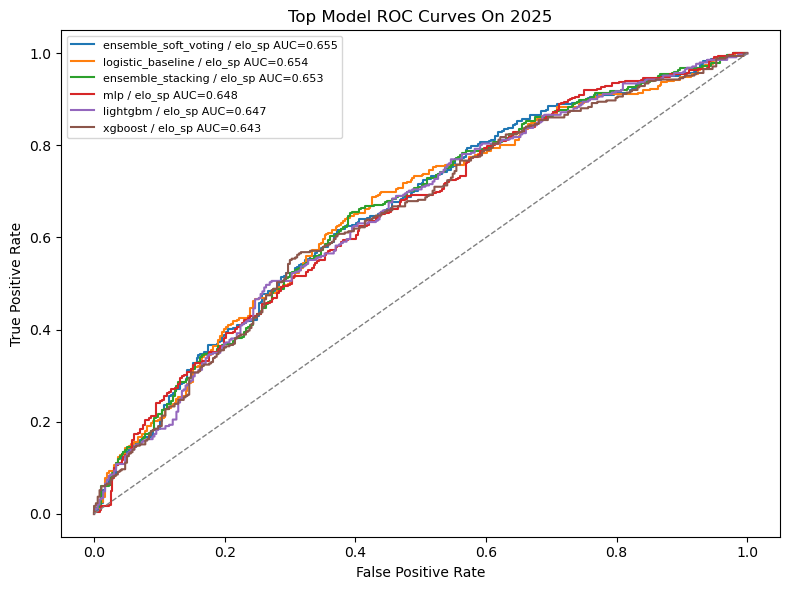

In [14]:
plt.figure(figsize=(8, 6))
for _, row in results_df.head(8).iterrows():
    target = predictions_df[
        (predictions_df["model"] == row["model"])
        & (predictions_df["feature_set"] == row["feature_set"])
    ]
    if len(target) == 0:
        continue
    fpr, tpr, _ = roc_curve(target["y_true"].astype(int), target["y_proba"].astype(float))
    plt.plot(fpr, tpr, label=f"{row['model']} / {row['feature_set']} AUC={row['eval_auc']:.3f}")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Top Model ROC Curves On 2025")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [15]:
ARTIFACT_DIR = Path("modeling_5th_outputs")
ARTIFACT_DIR.mkdir(exist_ok=True)

results_df.to_csv(ARTIFACT_DIR / "modeling_5th_results.csv", index=False, encoding="utf-8-sig")
all_tuning_df.to_csv(ARTIFACT_DIR / "modeling_5th_tuning.csv", index=False, encoding="utf-8-sig")
predictions_df.to_csv(ARTIFACT_DIR / "modeling_5th_predictions_2025.csv", index=False, encoding="utf-8-sig")
best_metric_summary.to_csv(ARTIFACT_DIR / "modeling_5th_best_by_metric.csv", index=False, encoding="utf-8-sig")

# 저장할 대표 모델은 AUC 기준 best로 선택한다.
best_row = results_df.loc[results_df["eval_auc"].idxmax()]
best_key = (best_row["feature_set"], best_row["model"])
if best_key in best_models:
    joblib.dump(best_models[best_key], ARTIFACT_DIR / "modeling_5th_best_model_auc.pkl")
else:
    print("AUC best model is an ensemble; rebuild from the best_params column when finalizing for production.")

joblib.dump(FEATURE_COLS, ARTIFACT_DIR / "modeling_5th_elo_sp_feature_cols.pkl")

print(f"saved outputs to: {ARTIFACT_DIR.resolve()}")
for row in best_metric_summary.itertuples(index=False):
    direction = "higher is better" if row.metric in ["accuracy", "AUC"] else "lower is better"
    print(f"best {row.metric}: {row.best_model} ({row.feature_set}) score={row.score:.4f} [{direction}]")


AUC best model is an ensemble; rebuild from the best_params column when finalizing for production.
saved outputs to: C:\Users\User\Desktop\statiz_prediction\modeling_5th_outputs
best accuracy: logistic_baseline (elo_sp) score=0.6262 [higher is better]
best AUC: ensemble_soft_voting (elo_sp) score=0.6550 [higher is better]
best brier_score: ensemble_soft_voting (elo_sp) score=0.2319 [lower is better]
